# ***Importing Libraries***

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
import warnings
warnings.filterwarnings('ignore')

SEED = 42

# ***Exploratory Data Analysis (EDA)***

In [28]:
wine = load_wine(as_frame=True)
df = wine.data
labels_true = wine.target
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [29]:
df.tail()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.7,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.3,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.2,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.3,0.60,1.62,840.0
177,14.13,4.10,2.74,24.5,96.0,2.05,0.76,0.56,1.35,9.2,0.61,1.60,560.0


In [30]:
df.shape

(178, 13)

In [31]:
df.columns

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline'],
      dtype='object')

In [32]:
df.dtypes

,0
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

In [34]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
df.isnull().sum() / df.shape[0] * 100

,0
alcohol,0.0
malic_acid,0.0
ash,0.0
alcalinity_of_ash,0.0
magnesium,0.0
total_phenols,0.0
flavanoids,0.0
nonflavanoid_phenols,0.0
proanthocyanins,0.0
color_intensity,0.0


# ***Data Visualization***

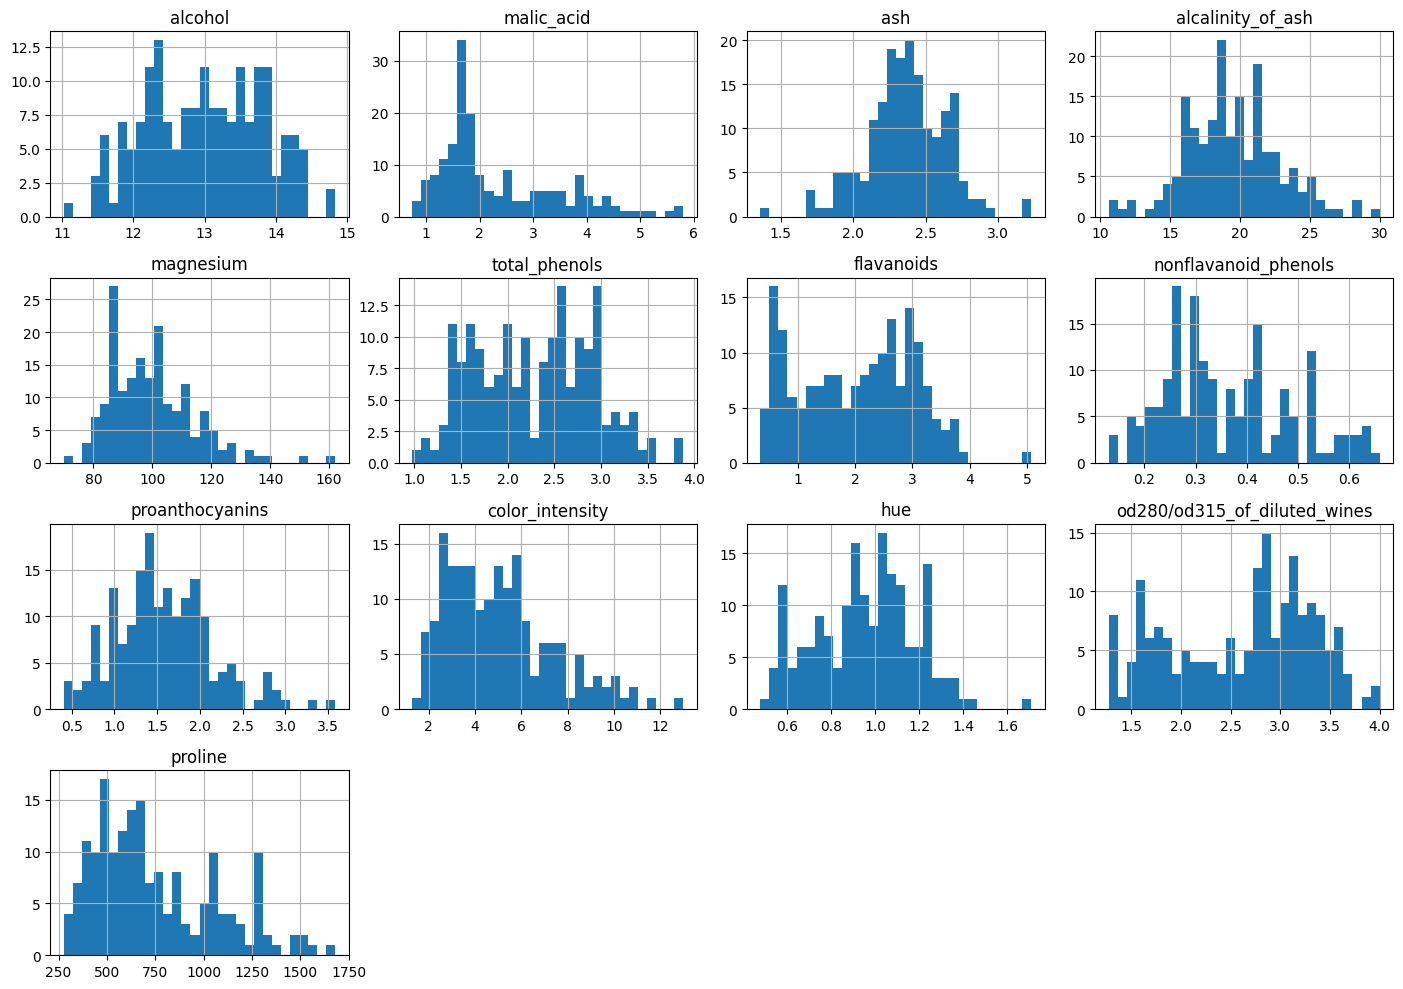

In [37]:
df.hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

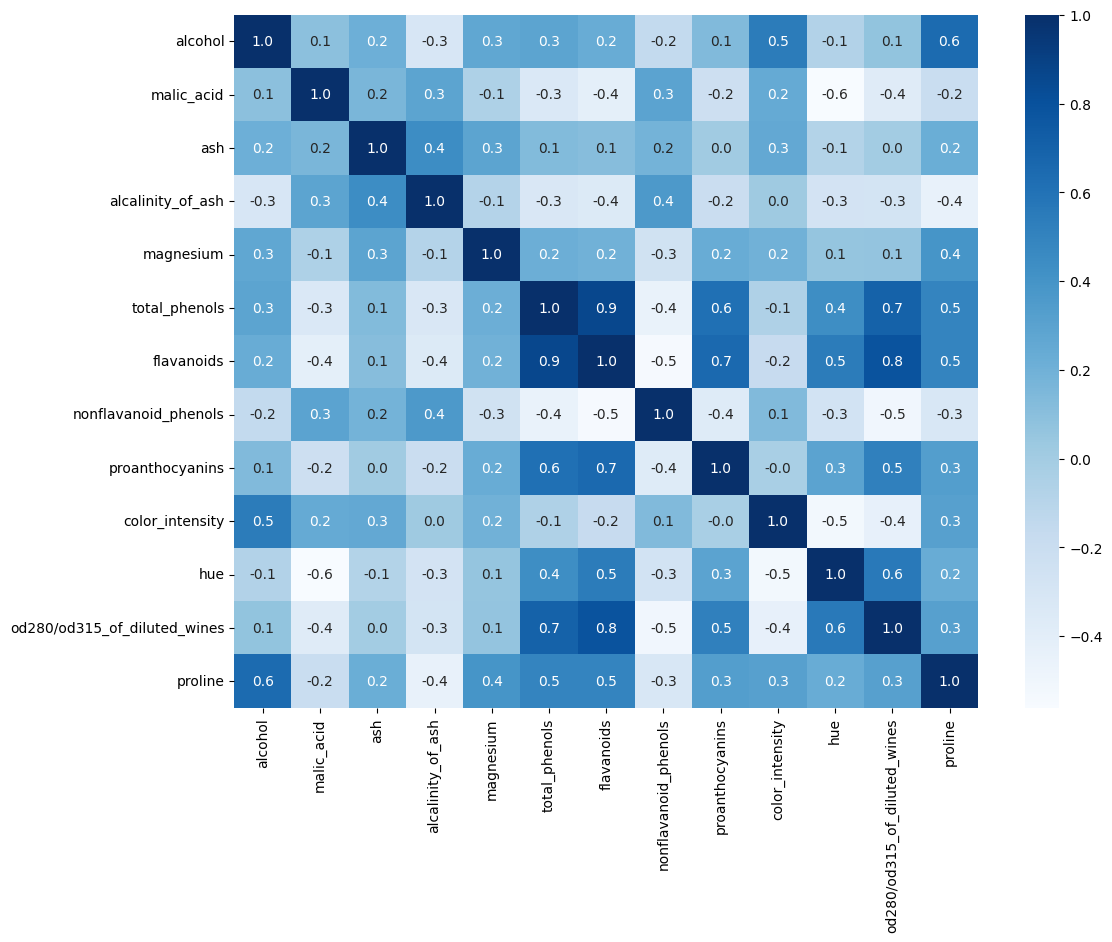

In [38]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt='.1f', cmap='Blues')
plt.show()

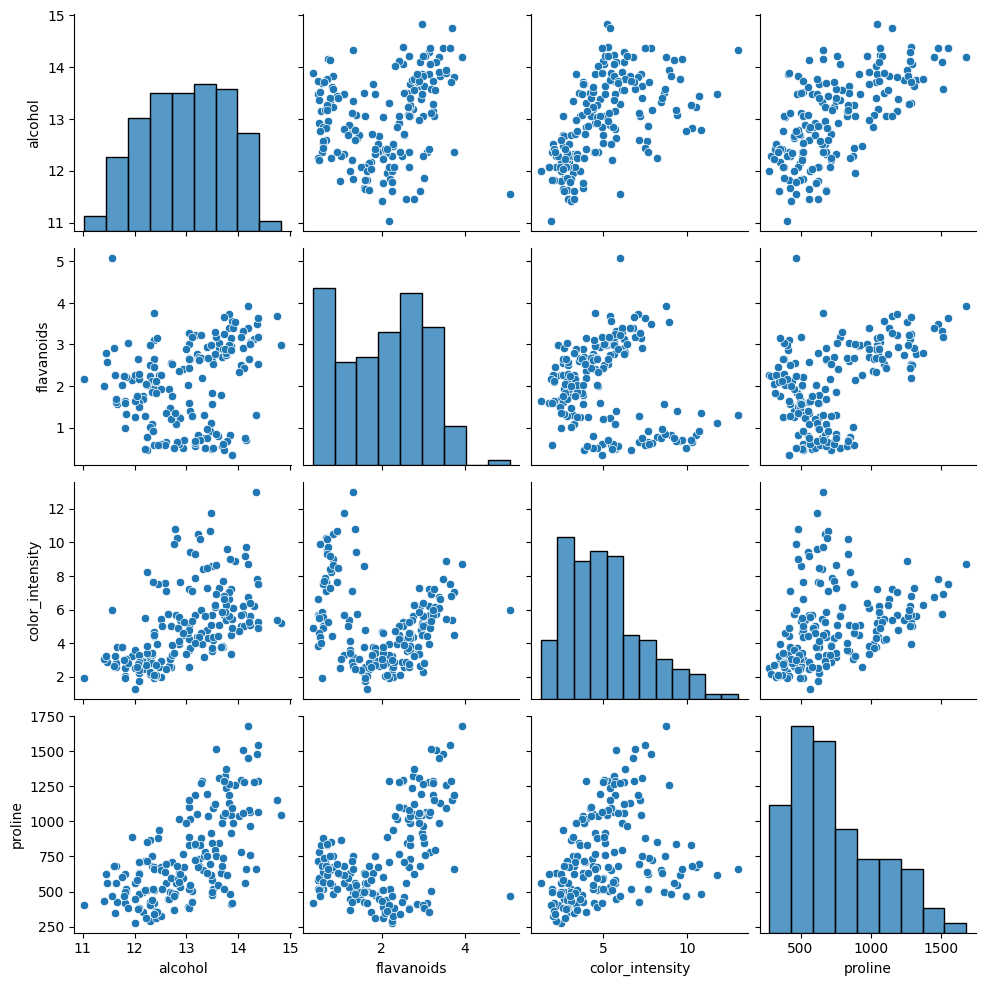

In [39]:
sns.pairplot(df[['alcohol', 'flavanoids', 'color_intensity', 'proline']])
plt.show()

# ***Data Preprocessing***

In [40]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
X_scaled.shape

(178, 13)

In [41]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
print(pca.explained_variance_ratio_)

[0.36198848 0.1920749 ]


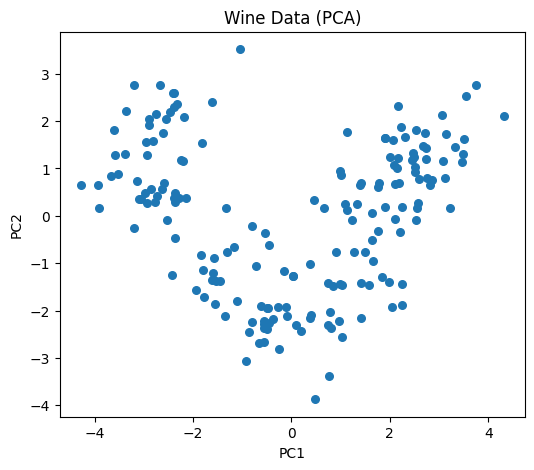

In [42]:
plt.figure(figsize=(6, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=30)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Wine Data (PCA)')
plt.show()

# ***Finding the Best K***

In [43]:
results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = model.fit_predict(X_scaled)
    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels)
    })

k_results = pd.DataFrame(results)
k_results

,K,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,1658.758852,0.259317,1.525997,69.523332
1,3,1277.928489,0.284859,1.389188,70.940008
2,4,1175.428333,0.260170,1.796892,56.181355
3,5,1109.512739,0.201619,1.808319,46.952209
4,6,1046.002333,0.237167,1.554394,41.700786
5,7,981.595233,0.203628,1.660585,38.685534
6,8,935.201211,0.157014,1.740859,35.805250
7,9,889.892911,0.149882,1.708276,33.806610
8,10,845.895237,0.143638,1.706970,32.397182


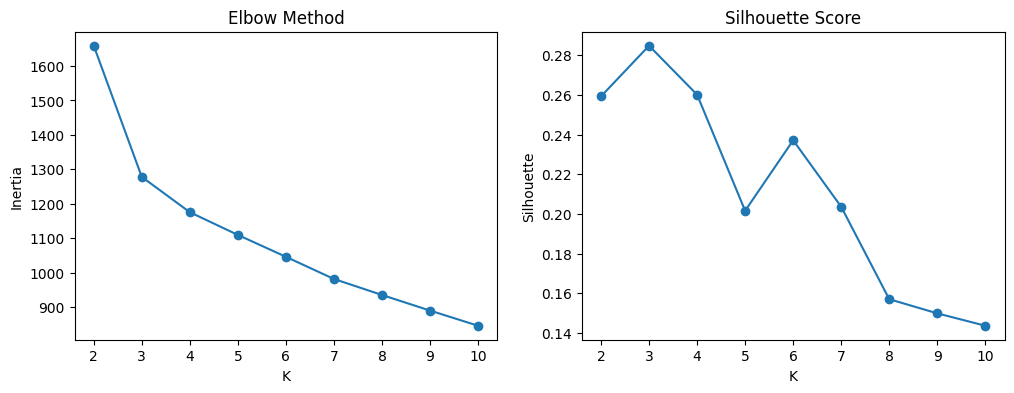

In [44]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_results['K'], k_results['Inertia'], marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(k_results['K'], k_results['Silhouette'], marker='o')
plt.title('Silhouette Score')
plt.xlabel('K')
plt.ylabel('Silhouette')

plt.show()

# ***KMeans Model***

In [45]:
kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

In [46]:
pd.Series(clusters).value_counts().sort_index()

,count
0,65
1,51
2,62


# ***Evaluating the Clusters***

In [47]:
print("Silhouette:", silhouette_score(X_scaled, clusters))
print("Davies-Bouldin:", davies_bouldin_score(X_scaled, clusters))
print("Calinski-Harabasz:", calinski_harabasz_score(X_scaled, clusters))

Silhouette: 0.2848589191898987
Davies-Bouldin: 1.3891879777181648
Calinski-Harabasz: 70.94000800315118


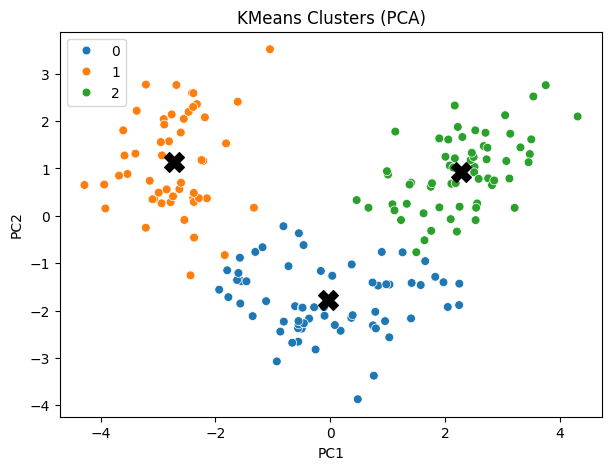

In [48]:
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette='tab10', s=40)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', marker='X', s=200)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('KMeans Clusters (PCA)')
plt.show()

In [49]:
df.assign(Cluster=clusters).groupby('Cluster').mean()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Cluster,,,,,,,,,,,,,
0,12.250923,1.897385,2.231231,20.063077,92.738462,2.247692,2.050000,0.357692,1.624154,2.973077,1.062708,2.803385,510.169231
1,13.134118,3.307255,2.417647,21.241176,98.666667,1.683922,0.818824,0.451961,1.145882,7.234706,0.691961,1.696667,619.058824
2,13.676774,1.997903,2.466290,17.462903,107.967742,2.847581,3.003226,0.292097,1.922097,5.453548,1.065484,3.163387,1100.225806


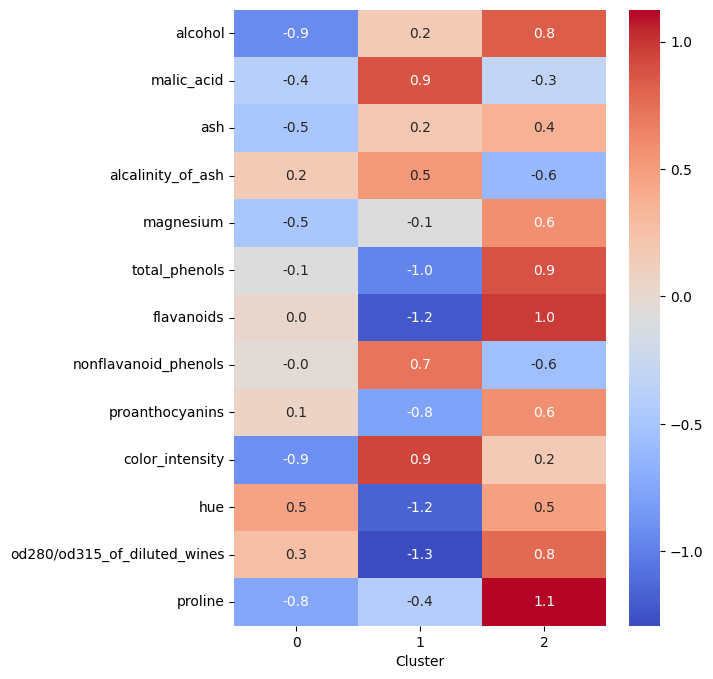

In [50]:
centers_df = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)

plt.figure(figsize=(6, 8))
sns.heatmap(centers_df.T, annot=True, fmt='.1f', cmap='coolwarm')
plt.xlabel('Cluster')
plt.show()

# ***Comparing with the Real Wine Types***

In [51]:
print("Adjusted Rand Index:", adjusted_rand_score(labels_true, clusters))
pd.crosstab(labels_true, clusters, rownames=['Real Type'], colnames=['Cluster'])

Adjusted Rand Index: 0.8974949815093207


Cluster,0,1,2
Real Type,,,
0,0,0,59
1,65,3,3
2,0,48,0


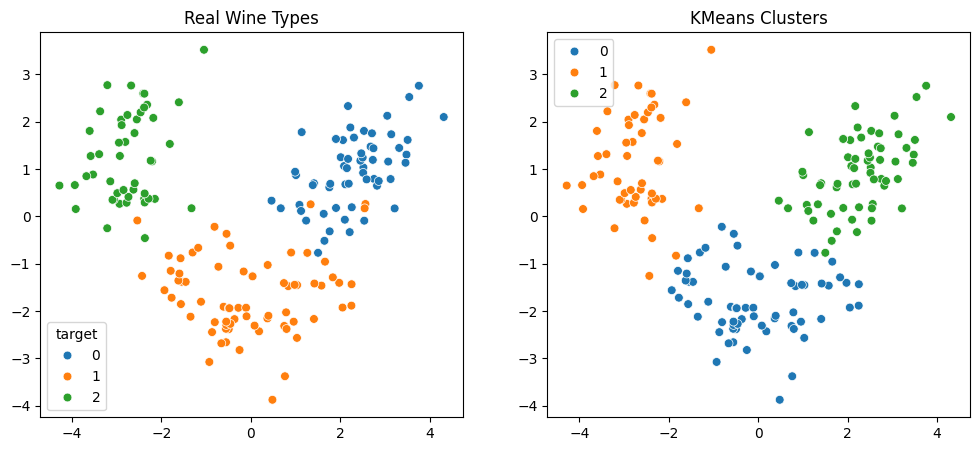

In [52]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_true, palette='tab10', s=40)
plt.title('Real Wine Types')

plt.subplot(1, 2, 2)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette='tab10', s=40)
plt.title('KMeans Clusters')

plt.show()